In [16]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv

load_dotenv(override=True)

llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite"
)

### Define State

In [4]:
class QAState(TypedDict):
    question: str
    answer: str

### Single Node (Ask the LLM)

In [7]:
def ask_llm(state: QAState) -> dict:
    response = llm.invoke(state["question"])

    state["answer"] = response.content

    return state

### Define and Compile Graph

In [9]:
graph = StateGraph(QAState)

graph.add_node("ask_llm", ask_llm)

graph.add_edge(START, "ask_llm")
graph.add_edge("ask_llm", END)

workflow = graph.compile()

### Execute Graph

In [17]:
initial_state = {
    "question": "What is LangGraph?",
    "answer": ""
}

final_state = workflow.invoke(initial_state)

print("Question:", final_state["question"])
print("Answer:", final_state["answer"])

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


Question: What is LangGraph?
Answer: [{'type': 'text', 'text': '**LangGraph** is an open-source library developed by LangChain designed to build **stateful, multi-agent applications** with Large Language Models (LLMs). \n\nWhile standard LLM frameworks are great for linear chains of commands (e.g., Prompt -> LLM -> Output), LangGraph allows you to build complex workflows where agents need to **loops, make decisions, collaborate, and maintain memory** over multiple steps.\n\nHere is a breakdown of what makes LangGraph unique, why it’s used, and how it works.\n\n---\n\n### 1. The Core Problem LangGraph Solves\nMost LLM applications follow a **Directed Acyclic Graph (DAG)**—they move in a straight line from start to finish. However, real-world AI applications often need to be cyclical. \n\nFor example, consider an AI programmer agent:\n1. Write code.\n2. Test the code.\n3. Did it pass? \n   * **If no:** Send the error back to step 1 (a loop).\n   * **If yes:** Finish.\n\nStandard chains s

### Visualize graph

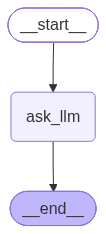

In [18]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())